<a href="https://colab.research.google.com/github/KenNicholas/komparatif-genai/blob/main/komparatif_genai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Setup dan Import Awal


In [1]:
# import
import torch, numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

print('pytorch:', torch.__version__)
print('gpu:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu')

pytorch: 2.14.1+cu130
gpu: Tesla T4


## Load dataset FashionMNIST

In [2]:
tf = transforms.Compose([transforms.ToTensor()])
train_full = datasets.FashionMNIST(root='./data', train=True, download=True, transform=tf)
test_full = datasets.FashionMNIST(root='./data', train=False, download=True, transform=tf)

print('Train: ', len(train_full))
print('Test: ', len(test_full))

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 165kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.16MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 6.04MB/s]

Train:  60000
Test:  10000


In [3]:
x = np.concatenate([
    np.stack([train_full[i][0].numpy() for i in range(len(train_full))]),
    np.stack([test_full[i][0].numpy()  for i in range(len(test_full))])
], axis=0)

y = np.concatenate([
    np.array([train_full[i][1] for i in range(len(train_full))]),
    np.array([test_full[i][1]  for i in range(len(test_full))])
], axis=0)

print('Digabung: ')
print('Total: ', len(x))
print('Classes: ', train_full.classes)

Digabung: 
Total:  70000
Classes:  ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## EDA

In [4]:
from collections import Counter

counts = Counter(y.tolist())

for i in sorted(counts):
  print(f'{i:2d} {train_full.classes[i]:12s} {counts[i]}')

 0 T-shirt/top  7000
 1 Trouser      7000
 2 Pullover     7000
 3 Dress        7000
 4 Coat         7000
 5 Sandal       7000
 6 Shirt        7000
 7 Sneaker      7000
 8 Bag          7000
 9 Ankle boot   7000


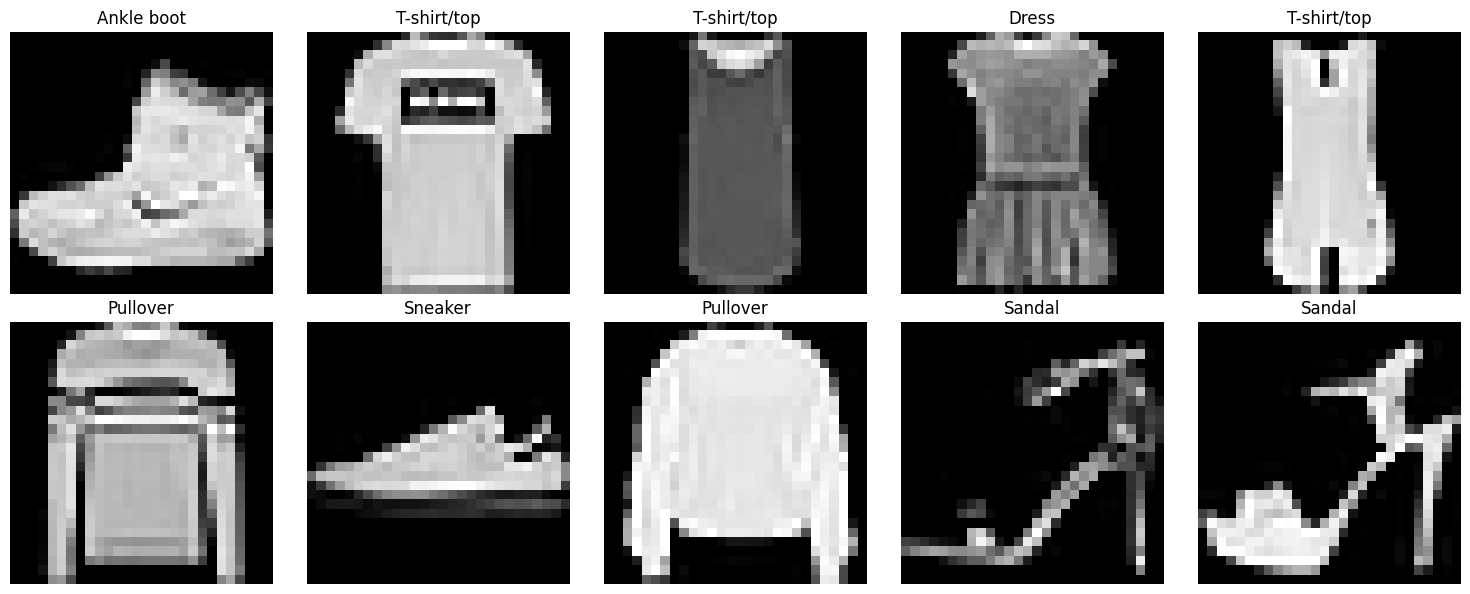

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(15,6))

for ax,i in zip(axes.flat, range(10)):
  img, label = train_full[i]
  ax.imshow(img.squeeze(), cmap='gray')
  ax.set_title(train_full.classes[label])
  ax.axis('off')

plt.tight_layout()
plt.show()

## Train test split (80/10/10)

In [6]:
from sklearn.model_selection import train_test_split

x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [7]:
train_set = TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train))
val_set = TensorDataset(torch.from_numpy(x_val), torch.from_numpy(y_val))
test_set = TensorDataset(torch.from_numpy(x_test), torch.from_numpy(y_test))

print('Train: ', len(train_set))
print('Validation: ', len(val_set))
print('Test: ', len(test_set))

Train:  56000
Validation:  7000
Test:  7000


## Dataloader

In [8]:
train = DataLoader(train_set, batch_size=128, shuffle=True)
val = DataLoader(val_set,   batch_size=128, shuffle=False)
test = DataLoader(test_set,  batch_size=128, shuffle=False)

## simpan utils.py dan data.py

In [9]:
!mkdir -p src

In [10]:
%%writefile src/utils.py
import torch, numpy as np, random, json, os

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def get_device():
    return torch.device('cuda' if torch.cuda.is_available() else 'cpu')

Writing src/utils.py


In [11]:
%%writefile src/data.py
import numpy as np
import torch
from torchvision import datasets, transforms
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

def get_loaders(batch_size=128, seed=42):
    tf = transforms.Compose([transforms.ToTensor()])
    train_full = datasets.FashionMNIST(root='./data', train=True,  download=True, transform=tf)
    test_full  = datasets.FashionMNIST(root='./data', train=False, download=True, transform=tf)

    x = np.concatenate([
        np.stack([train_full[i][0].numpy() for i in range(len(train_full))]),
        np.stack([test_full[i][0].numpy()  for i in range(len(test_full))])
    ], axis=0)
    y = np.concatenate([
        np.array([train_full[i][1] for i in range(len(train_full))]),
        np.array([test_full[i][1]  for i in range(len(test_full))])
    ], axis=0)

    x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=seed, stratify=y)
    x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=seed, stratify=y_temp)

    train_set = TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train))
    val_set = TensorDataset(torch.from_numpy(x_val), torch.from_numpy(y_val))
    test_set = TensorDataset(torch.from_numpy(x_test), torch.from_numpy(y_test))

    return (DataLoader(train_set, batch_size=batch_size, shuffle=True),
            DataLoader(val_set,batch_size=batch_size, shuffle=False),
            DataLoader(test_set,batch_size=batch_size, shuffle=False))

Writing src/data.py


# 2. Vanilla AutoEncoder

In [12]:
import torch, torch.nn as nn, torch.nn.functional as F, time
from src.data import get_loaders
from src.utils import set_seed, get_device

class VanillaAE(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, z_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(z_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid()
        )
    def forward(self, x):
        z = self.encoder(x.flatten(1))
        return self.decoder(z), z

def train_vanilla_ae(epochs=30, lr=1e-3, batch_size=128, seed=42):
    set_seed(seed)
    device = get_device()
    train, val, test = get_loaders(batch_size, seed)
    model = VanillaAE().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train': [], 'val': []}
    best_val, best_state, best_epoch = float('inf'), None, -1
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        train_loss_sum = 0
        for images, _ in train:
            images = images.to(device)
            optimizer.zero_grad()
            xr, _ = model(images)
            loss = F.mse_loss(xr, images.flatten(1))
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * images.size(0)
        history['train'].append(train_loss_sum / len(train.dataset))

        model.eval()
        val_loss_sum = 0
        with torch.no_grad():
            for images, _ in val:
                images = images.to(device)
                xr, _ = model(images)
                val_loss_sum += F.mse_loss(xr, images.flatten(1)).item() * images.size(0)
        history['val'].append(val_loss_sum / len(val.dataset))

        if history['val'][-1] < best_val:
            best_val = history['val'][-1]
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
            best_epoch = epoch + 1

        train_loss = history['train'][-1]
        val_loss = history['val'][-1]
        print(f'Epoch {epoch+1:02d} : train {train_loss:.5f} , val {val_loss:.5f}')

    model.load_state_dict(best_state)
    return model, history, (time.time() - start_time) / epochs, best_epoch, best_val

In [13]:
# train 30 epoch
model_ae, hist_ae, sec_ae, best_ep_ae, best_val_ae = train_vanilla_ae()
print('='*25)
print(f'best_ep={best_ep_ae} best_val={best_val_ae:.5f} , sec/epoch={sec_ae:.2f}')

Epoch 01 : train 0.03173 , val 0.01859
Epoch 02 : train 0.01655 , val 0.01499
Epoch 03 : train 0.01390 , val 0.01306
Epoch 04 : train 0.01243 , val 0.01189
Epoch 05 : train 0.01133 , val 0.01102
Epoch 06 : train 0.01058 , val 0.01033
Epoch 07 : train 0.00997 , val 0.00997
Epoch 08 : train 0.00950 , val 0.00953
Epoch 09 : train 0.00910 , val 0.00910
Epoch 10 : train 0.00876 , val 0.00876
Epoch 11 : train 0.00844 , val 0.00849
Epoch 12 : train 0.00818 , val 0.00826
Epoch 13 : train 0.00795 , val 0.00810
Epoch 14 : train 0.00774 , val 0.00783
Epoch 15 : train 0.00756 , val 0.00774
Epoch 16 : train 0.00741 , val 0.00759
Epoch 17 : train 0.00724 , val 0.00742
Epoch 18 : train 0.00711 , val 0.00728
Epoch 19 : train 0.00702 , val 0.00718
Epoch 20 : train 0.00690 , val 0.00708
Epoch 21 : train 0.00680 , val 0.00702
Epoch 22 : train 0.00673 , val 0.00693
Epoch 23 : train 0.00664 , val 0.00684
Epoch 24 : train 0.00657 , val 0.00676
Epoch 25 : train 0.00651 , val 0.00670
Epoch 26 : train 0.00646 

In [14]:
# metrik evaluasi: MSE, PSNR, SSIM, latency GPU, Variance of Laplacian
import numpy as np
from skimage.metrics import peak_signal_noise_ratio as psnr_fn, structural_similarity as ssim_fn
from scipy.ndimage import laplace

device = get_device()
_, _, test = get_loaders()
model_ae.eval()
mse_sum = 0
psnr_sum = 0
ssim_sum = 0
lap_sum = 0
n = 0
with torch.no_grad():
    for images, _ in test:
        images = images.to(device)
        xr, _ = model_ae(images)
        for i in range(images.size(0)):
            asli = images[i,0].cpu().numpy()
            rekonstruksi = xr[i].cpu().reshape(28,28).numpy()
            mse_sum  += float(((asli-rekonstruksi)**2).mean())
            psnr_sum += psnr_fn(asli, rekonstruksi, data_range=1.0)
            ssim_sum += ssim_fn(asli, rekonstruksi, data_range=1.0)
            lap_sum  += laplace(asli).var()
            n += 1

mse_ae = mse_sum / n
psnr_ae = psnr_sum / n
ssim_ae = ssim_sum / n
laplacian_ae = lap_sum / n

batch_64 = next(iter(test))[0][:64].to(device)
for _ in range(10):
    model_ae(batch_64)
torch.cuda.synchronize()
start_time = time.time()
for _ in range(50):
    model_ae(batch_64)
torch.cuda.synchronize()
latency_ae = (time.time() - start_time) / 50 * 1000

print('Vanilla AutoEncoder')
print('='*25)
print(f'MSE {mse_ae:.3f}')
print(f'PSNR {psnr_ae:.2f}')
print(f'SSIM {ssim_ae:.3f}')
print(f'Variance of Laplacian: {laplacian_ae:.2f}')
print(f'latency GPU: {latency_ae:.2f}ms')

Vanilla AutoEncoder
MSE 0.006
PSNR 23.02
SSIM 0.828
Variance of Laplacian: 0.16
latency GPU: 0.22ms


In [15]:
# Perbandingan antara Variance of Laplacian: asli dan rekonstruksi
import numpy as np
from scipy.ndimage import laplace

model_ae.eval()
laplacian_real = 0
laplacian_recon = 0
n = 0

with torch.no_grad():
    for images, _ in test:
        images = images.to(device)
        xr, _ = model_ae(images)
        for i in range(images.size(0)):
            asli = images[i, 0].cpu().numpy()
            rekonstruksi = xr[i].cpu().reshape(28, 28).numpy()
            laplacian_real += laplace(asli).var()
            laplacian_recon += laplace(rekonstruksi).var()
            n += 1

laplacian_real = laplacian_real/n
laplacian_reconstruction = laplacian_recon/n

print(f'Laplacian asli : {laplacian_real:.3f}')
print(f'Laplacian rekonstruksi : {laplacian_reconstruction:.3f}')
print(f'Rasio rekonstruksi/asli: {laplacian_reconstruction / laplacian_real:.3f}')

Laplacian asli : 0.164
Laplacian rekonstruksi : 0.082
Rasio rekonstruksi/asli: 0.501


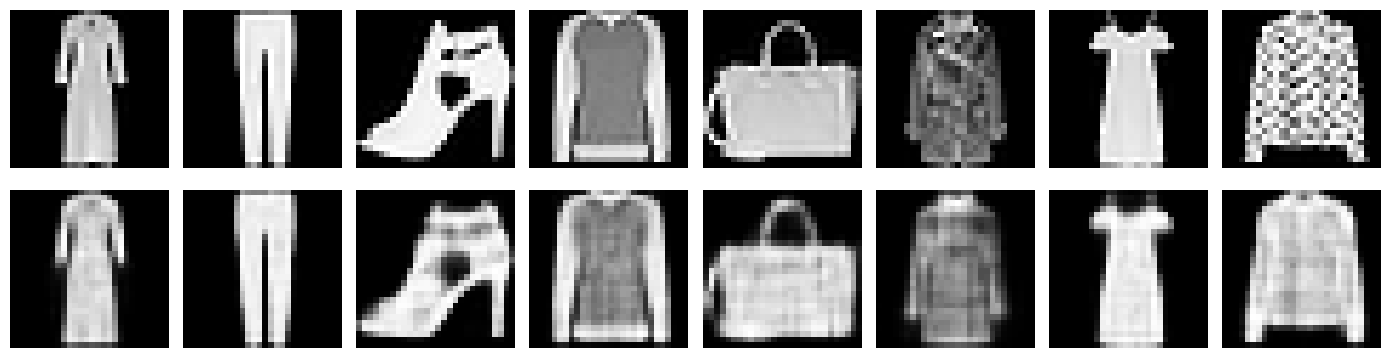

In [16]:
import matplotlib.pyplot as plt
images, _ = next(iter(test));
images = images[:8].to(device)
with torch.no_grad():
  xr, _ = model_ae(images)

fig, ax = plt.subplots(2, 8, figsize=(14,4))
for i in range(8):
    ax[0,i].imshow(images[i,0].cpu(), cmap='gray')
    ax[0,i].axis('off')
    ax[1,i].imshow(xr[i].cpu().reshape(28,28), cmap='gray')
    ax[1,i].axis('off')
plt.tight_layout();
plt.show()

In [17]:
%%writefile src/vanilla_ae.py
import torch, torch.nn as nn, torch.nn.functional as F, time
from src.data import get_loaders
from src.utils import set_seed, get_device

class VanillaAE(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, z_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(z_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid()
        )
    def forward(self, x):
        z = self.encoder(x.flatten(1))
        return self.decoder(z), z

def train_vanilla_ae(epochs=30, lr=1e-3, batch_size=128, seed=42):
    set_seed(seed)
    device = get_device()
    train, val, test = get_loaders(batch_size, seed)
    model = VanillaAE().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train': [], 'val': []}
    best_val, best_state, best_epoch = float('inf'), None, -1
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        train_loss_sum = 0
        for images, _ in train:
            images = images.to(device)
            optimizer.zero_grad()
            reconstruction, _ = model(images)
            loss = F.mse_loss(reconstruction, images.flatten(1))
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * images.size(0)
        history['train'].append(train_loss_sum / len(train.dataset))

        model.eval()
        val_loss_sum = 0
        with torch.no_grad():
            for images, _ in val:
                images = images.to(device)
                reconstruction, _ = model(images)
                val_loss_sum += F.mse_loss(reconstruction, images.flatten(1)).item() * images.size(0)
        history['val'].append(val_loss_sum / len(val.dataset))

        if history['val'][-1] < best_val:
            best_val = history['val'][-1]
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
            best_epoch = epoch + 1

        train_loss = history['train'][-1]
        val_loss = history['val'][-1]
        print(f'epoch {epoch+1:02d} train {train_loss:.5f} val {val_loss:.5f}')

    model.load_state_dict(best_state)
    return model, history, (time.time() - start_time) / epochs, best_epoch, best_val

Writing src/vanilla_ae.py


## 3. Sparse AutoEncoder

In [18]:
import torch, torch.nn as nn, torch.nn.functional as F, time
from src.data import get_loaders
from src.utils import set_seed, get_device

class SparseAE(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, z_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(z_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid()
        )
    def forward(self, x):
        h = self.encoder[1](self.encoder[0](x.flatten(1)))
        z = self.encoder[2](h)
        return self.decoder(z), z, h

def train_sparse_ae(epochs=30, lr=1e-3, batch_size=128, seed=42, lam=1e-3):
    set_seed(seed)
    device = get_device()
    train, val, test = get_loaders(batch_size, seed)
    model = SparseAE().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train': [], 'val': []}
    best_val, best_state, best_epoch = float('inf'), None, -1
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        train_loss_sum = 0
        for images, _ in train:
            images = images.to(device)
            optimizer.zero_grad()
            xr, _, h = model(images)
            loss = F.mse_loss(xr, images.flatten(1)) + lam * h.abs().mean()
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * images.size(0)
        history['train'].append(train_loss_sum / len(train.dataset))

        model.eval()
        val_loss_sum = 0
        with torch.no_grad():
            for images, _ in val:
                images = images.to(device)
                xr, _, _ = model(images)
                val_loss_sum += F.mse_loss(xr, images.flatten(1)).item() * images.size(0)
        history['val'].append(val_loss_sum / len(val.dataset))

        if history['val'][-1] < best_val:
            best_val = history['val'][-1]
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
            best_epoch = epoch + 1

        train_loss = history['train'][-1]
        val_loss = history['val'][-1]
        print(f'Epoch {epoch+1:02d} : train {train_loss:.5f} , val {val_loss:.5f}')

    model.load_state_dict(best_state)
    return model, history, (time.time() - start_time) / epochs, best_epoch, best_val

In [19]:
model_sae, hist_sae, sec_sae, best_ep_sae, best_val_sae = train_sparse_ae()
print('='*25)
print(f'best_ep={best_ep_sae} best_val={best_val_sae:.5f} , sec/epoch={sec_sae:.2f}')

Epoch 01 : train 0.03216 , val 0.01865
Epoch 02 : train 0.01694 , val 0.01509
Epoch 03 : train 0.01437 , val 0.01318
Epoch 04 : train 0.01283 , val 0.01200
Epoch 05 : train 0.01180 , val 0.01130
Epoch 06 : train 0.01104 , val 0.01057
Epoch 07 : train 0.01045 , val 0.01004
Epoch 08 : train 0.00995 , val 0.00959
Epoch 09 : train 0.00955 , val 0.00920
Epoch 10 : train 0.00923 , val 0.00892
Epoch 11 : train 0.00890 , val 0.00865
Epoch 12 : train 0.00864 , val 0.00839
Epoch 13 : train 0.00843 , val 0.00823
Epoch 14 : train 0.00822 , val 0.00807
Epoch 15 : train 0.00805 , val 0.00793
Epoch 16 : train 0.00788 , val 0.00777
Epoch 17 : train 0.00773 , val 0.00758
Epoch 18 : train 0.00759 , val 0.00750
Epoch 19 : train 0.00748 , val 0.00735
Epoch 20 : train 0.00737 , val 0.00729
Epoch 21 : train 0.00727 , val 0.00718
Epoch 22 : train 0.00717 , val 0.00712
Epoch 23 : train 0.00710 , val 0.00703
Epoch 24 : train 0.00702 , val 0.00694
Epoch 25 : train 0.00695 , val 0.00692
Epoch 26 : train 0.00689 

In [20]:
# metrik evaluasi: MSE, PSNR, SSIM, latency GPU, Variance of Laplacian
import numpy as np
from skimage.metrics import peak_signal_noise_ratio as psnr_fn, structural_similarity as ssim_fn
from scipy.ndimage import laplace

device = get_device()
_, _, test = get_loaders()
model_sae.eval()
mse_sum = 0
psnr_sum = 0
ssim_sum = 0
lap_sum = 0
n = 0
with torch.no_grad():
    for images, _ in test:
        images = images.to(device)
        xr, _, _ = model_sae(images)
        for i in range(images.size(0)):
            asli = images[i,0].cpu().numpy()
            rekonstruksi = xr[i].cpu().reshape(28,28).numpy()
            mse_sum  += float(((asli-rekonstruksi)**2).mean())
            psnr_sum += psnr_fn(asli, rekonstruksi, data_range=1.0)
            ssim_sum += ssim_fn(asli, rekonstruksi, data_range=1.0)
            lap_sum  += laplace(asli).var()
            n += 1

mse_sae = mse_sum / n
psnr_sae = psnr_sum / n
ssim_sae = ssim_sum / n
laplacian_sae = lap_sum / n

batch_64 = next(iter(test))[0][:64].to(device)
for _ in range(10):
    model_sae(batch_64)
torch.cuda.synchronize()
waktu_mulai = time.time()
for _ in range(50):
    model_sae(batch_64)
torch.cuda.synchronize()
latency_sae = (time.time() - waktu_mulai) / 50 * 1000

print('SPARSE ENCODER')
print('='*25)
print(f'MSE {mse_sae:.3f}')
print(f'PSNR {psnr_sae:.2f}')
print(f'SSIM {ssim_sae:.3f}')
print(f'Variance of Laplacian: {laplacian_sae:.2f}')
print(f'latency GPU: {latency_sae:.2f}ms')

SPARSE ENCODER
MSE 0.007
PSNR 22.94
SSIM 0.827
Variance of Laplacian: 0.16
latency GPU: 0.24ms


In [21]:
# Perbandingan antara Variance of Laplacian: asli dan rekonstruksi
import numpy as np
from scipy.ndimage import laplace

model_ae.eval()
laplacian_real = 0
laplacian_recon = 0
n = 0

with torch.no_grad():
    for images, _ in test:
        images = images.to(device)
        xr, _ = model_ae(images)
        for i in range(images.size(0)):
            asli = images[i, 0].cpu().numpy()
            rekonstruksi = xr[i].cpu().reshape(28, 28).numpy()
            laplacian_real += laplace(asli).var()
            laplacian_recon += laplace(rekonstruksi).var()
            n += 1

laplacian_real = laplacian_real/n
laplacian_reconstruction = laplacian_recon/n

print(f'Laplacian asli : {laplacian_real:.3f}')
print(f'Laplacian rekonstruksi : {laplacian_reconstruction:.3f}')
print(f'Rasio rekonstruksi/asli: {laplacian_reconstruction / laplacian_real:.3f}')

Laplacian asli : 0.164
Laplacian rekonstruksi : 0.082
Rasio rekonstruksi/asli: 0.501


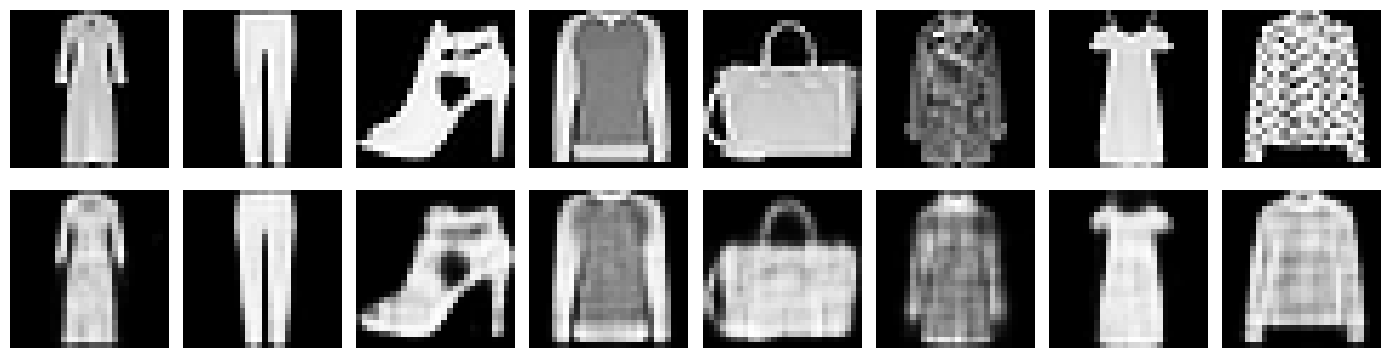

In [22]:
import matplotlib.pyplot as plt

images, _ = next(iter(test))
images = images[:8].to(device)
with torch.no_grad():
    xr, _, _ = model_sae(images)
fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for i in range(8):
    ax[0, i].imshow(images[i,0].cpu(), cmap='gray')
    ax[0, i].axis('off')
    ax[1, i].imshow(xr[i].cpu().reshape(28,28), cmap='gray')
    ax[1, i].axis('off')
plt.tight_layout()
plt.show()

In [23]:
%%writefile src/sparse_ae.py
import torch, torch.nn as nn, torch.nn.functional as F, time
from src.data import get_loaders
from src.utils import set_seed, get_device

class SparseAE(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, z_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(z_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid()
        )
    def forward(self, x):
        h = self.encoder[1](self.encoder[0](x.flatten(1)))
        z = self.encoder[2](h)
        return self.decoder(z), z, h

def train_sparse_ae(epochs=30, lr=1e-3, batch_size=128, seed=42, lam=1e-3):
    set_seed(seed)
    device = get_device()
    train, val, test = get_loaders(batch_size, seed)
    model = SparseAE().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train': [], 'val': []}
    best_val, best_state, best_epoch = float('inf'), None, -1
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        train_loss_sum = 0
        for images, _ in train:
            images = images.to(device)
            optimizer.zero_grad()
            xr, _, h = model(images)
            loss = F.mse_loss(xr, images.flatten(1)) + lam * h.abs().mean()
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * images.size(0)
        history['train'].append(train_loss_sum / len(train.dataset))

        model.eval()
        val_loss_sum = 0
        with torch.no_grad():
            for images, _ in val:
                images = images.to(device)
                xr, _, _ = model(images)
                val_loss_sum += F.mse_loss(xr, images.flatten(1)).item() * images.size(0)
        history['val'].append(val_loss_sum / len(val.dataset))

        if history['val'][-1] < best_val:
            best_val = history['val'][-1]
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
            best_epoch = epoch + 1

        train_loss = history['train'][-1]
        val_loss = history['val'][-1]
        print(f'Epoch {epoch+1:02d} : train {train_loss:.5f} , val {val_loss:.5f}')

    model.load_state_dict(best_state)
    return model, history, (time.time() - start_time) / epochs, best_epoch, best_val

Writing src/sparse_ae.py


In [24]:
# Vanilla vs Sparse
import numpy as np

def hitung_sparsity(model, test_loader, device):
    model.eval()
    activation = []
    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(device)
            h = model.encoder[1](model.encoder[0](images.flatten(1)))
            activation.append(h.cpu())
    h_all = torch.cat(activation, dim=0)
    persen_nol = (h_all == 0).float().mean().item() * 100
    persentil_99 = torch.quantile(h_all, 0.99)
    persen_kecil = (h_all < 0.01 * persentil_99).float().mean().item() * 100
    return persen_nol, persen_kecil

nol_vanilla, kecil_vanilla = hitung_sparsity(model_ae, test, device)
nol_sparse, kecil_sparse = hitung_sparsity(model_sae, test, device)

print('VANILLA AE vs SPARSE AE (activation 256-d)')
print('='*25)
print(f'Vanilla: activation nol {nol_vanilla:.2f}% , activation kecil {kecil_vanilla:.2f}%')
print(f'Sparse : activation nol {nol_sparse:.2f}% , activation kecil {kecil_sparse:.2f}%')

VANILLA AE vs SPARSE AE (activation 256-d)
Vanilla: activation nol 44.09% , activation kecil 44.45%
Sparse : activation nol 59.20% , activation kecil 59.73%


# 4. Variatonal AutoEncoder (VAE)

In [25]:
import torch, torch.nn as nn, torch.nn.functional as F, time
from src.data import get_loaders
from src.utils import set_seed, get_device

class VAE(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28*28, 256), nn.ReLU()
        )
        self.fc_mu = nn.Linear(256, z_dim)
        self.fc_logvar = nn.Linear(256, z_dim)
        self.decoder = nn.Sequential(
            nn.Linear(z_dim, 256), nn.ReLU(),
            nn.Linear(256, 28*28), nn.Sigmoid()
        )
    def encode(self, x):
        h = self.encoder(x.flatten(1))
        return self.fc_mu(h), self.fc_logvar(h)
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar, z

def train_vae(epochs=30, lr=1e-3, batch_size=128, seed=42):
    set_seed(seed)
    device = get_device()
    train, val, test = get_loaders(batch_size, seed)
    model = VAE().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train': [], 'val': []}
    best_val, best_state, best_epoch = float('inf'), None, -1
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        train_loss_sum = 0
        for images, _ in train:
            images = images.to(device)
            optimizer.zero_grad()
            xr, mu, logvar, _ = model(images)
            bce = F.binary_cross_entropy(xr, images.flatten(1), reduction='mean')
            kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / images.size(0) / (28*28)
            loss = bce + kl
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * images.size(0)
        history['train'].append(train_loss_sum / len(train.dataset))

        model.eval()
        val_loss_sum = 0
        with torch.no_grad():
            for images, _ in val:
                images = images.to(device)
                xr, mu, logvar, _ = model(images)
                bce = F.binary_cross_entropy(xr, images.flatten(1), reduction='mean')
                kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / images.size(0) / (28*28)
                val_loss_sum += (bce + kl).item() * images.size(0)
        history['val'].append(val_loss_sum / len(val.dataset))

        if history['val'][-1] < best_val:
            best_val = history['val'][-1]
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
            best_epoch = epoch + 1

        train_loss = history['train'][-1]
        val_loss = history['val'][-1]
        print(f'Epoch {epoch+1:02d} : train {train_loss:.5f} , val {val_loss:.5f}')

    model.load_state_dict(best_state)
    return model, history, (time.time() - start_time) / epochs, best_epoch, best_val

In [26]:
model_vae, hist_vae, sec_vae, best_ep_vae, best_val_vae = train_vae()
print('='*25)
print(f'best_ep={best_ep_vae} best_val={best_val_vae:.5f} , sec/epoch={sec_vae:.2f}')

Epoch 01 : train 0.38380 , val 0.35097
Epoch 02 : train 0.34331 , val 0.33880
Epoch 03 : train 0.33222 , val 0.32859
Epoch 04 : train 0.32460 , val 0.32274
Epoch 05 : train 0.32016 , val 0.31927
Epoch 06 : train 0.31725 , val 0.31719
Epoch 07 : train 0.31547 , val 0.31558
Epoch 08 : train 0.31418 , val 0.31462
Epoch 09 : train 0.31319 , val 0.31385
Epoch 10 : train 0.31235 , val 0.31299
Epoch 11 : train 0.31184 , val 0.31313
Epoch 12 : train 0.31126 , val 0.31204
Epoch 13 : train 0.31086 , val 0.31197
Epoch 14 : train 0.31048 , val 0.31136
Epoch 15 : train 0.31014 , val 0.31094
Epoch 16 : train 0.30981 , val 0.31075
Epoch 17 : train 0.30958 , val 0.31048
Epoch 18 : train 0.30930 , val 0.31054
Epoch 19 : train 0.30915 , val 0.30999
Epoch 20 : train 0.30892 , val 0.30997
Epoch 21 : train 0.30872 , val 0.30974
Epoch 22 : train 0.30858 , val 0.30987
Epoch 23 : train 0.30843 , val 0.30962
Epoch 24 : train 0.30831 , val 0.30930
Epoch 25 : train 0.30813 , val 0.30932
Epoch 26 : train 0.30798 

In [27]:
# metrik evaluasi : MSE, PSNR, SSIM, latency, Variance of Laplacian
import numpy as np
from skimage.metrics import peak_signal_noise_ratio as psnr_fn, structural_similarity as ssim_fn
from scipy.ndimage import laplace

device = get_device()
_, _, test = get_loaders()
model_vae.eval()
mse_sum = 0
psnr_sum = 0
ssim_sum = 0
lap_sum = 0
n = 0
with torch.no_grad():
    for images, _ in test:
        images = images.to(device)
        mu, _ = model_vae.encode(images)
        xr = model_vae.decoder(mu)
        for i in range(images.size(0)):
            asli = images[i,0].cpu().numpy()
            rekonstruksi = xr[i].cpu().reshape(28,28).numpy()
            mse_sum  += float(((asli-rekonstruksi)**2).mean())
            psnr_sum += psnr_fn(asli, rekonstruksi, data_range=1.0)
            ssim_sum += ssim_fn(asli, rekonstruksi, data_range=1.0)
            lap_sum  += laplace(asli).var()
            n += 1

mse_vae = mse_sum / n
psnr_vae = psnr_sum / n
ssim_vae = ssim_sum / n
laplacian_vae = lap_sum / n

batch_64 = next(iter(test))[0][:64].to(device)
for _ in range(10):
    model_vae(batch_64)
torch.cuda.synchronize()
waktu_mulai = time.time()
for _ in range(50):
    model_vae(batch_64)
torch.cuda.synchronize()
latency_vae = (time.time() - waktu_mulai) / 50 * 1000

print('VAE')
print('='*25)
print(f'MSE {mse_vae:.3f}')
print(f'PSNR  {psnr_vae:.2f}')
print(f'SSIM {ssim_vae:.3f}')
print(f'Variance of Laplacian: {laplacian_vae:.2f}')
print(f'latency GPU: {latency_vae:.2f}ms')

VAE
MSE 0.013
PSNR  19.72
SSIM 0.709
Variance of Laplacian: 0.16
latency GPU: 0.40ms


In [28]:
# perbandingan Variance of Laplacian: asli dan rekonstruksi
import numpy as np
from scipy.ndimage import laplace

model_vae.eval()
lap_sum_real = 0
lap_sum_recon = 0
n = 0
with torch.no_grad():
    for images, _ in test:
        images = images.to(device)
        mu, _ = model_vae.encode(images)
        xr = model_vae.decoder(mu)
        for i in range(images.size(0)):
            asli = images[i,0].cpu().numpy()
            rekonstruksi = xr[i].cpu().reshape(28,28).numpy()
            lap_sum_real += laplace(asli).var()
            lap_sum_recon += laplace(rekonstruksi).var()
            n += 1

laplacian_real = lap_sum_real / n
laplacian_reconstruction = lap_sum_recon / n
print(f'Laplacian asli : {laplacian_real:.3f}')
print(f'Laplacian rekonstruksi : {laplacian_reconstruction:.3f}')
print(f'Rasio rekonstruksi/asli: {laplacian_reconstruction / laplacian_real:.2f}')

Laplacian asli : 0.164
Laplacian rekonstruksi : 0.048
Rasio rekonstruksi/asli: 0.29


In [29]:
# FID: sampel N(0,I) dan 5000 citra test
!pip -q install torchmetrics[image]
import torch
from torchmetrics.image.fid import FrechetInceptionDistance

device = get_device()
model_vae.eval()
_, _, test = get_loaders()

#ambil 5000 citra test
real = []
jumlah = 0
for images, _ in test:
    real.append(images)
    jumlah += images.size(0)
    if jumlah >= 5000:
        break
real = torch.cat(real, dim=0)[:5000]

# sampel 5000 dari N(0,I)
with torch.no_grad():
    z = torch.randn(5000, 64, device=device)
    fake = model_vae.decoder(z).reshape(5000, 1, 28, 28).cpu()

fid = FrechetInceptionDistance(feature=2048, normalize=True).to(device)

batch = 256
with torch.no_grad():
    for i in range(0, 5000, batch):
        r = real[i:i+batch].to(device).repeat(1, 3, 1, 1)
        f = fake[i:i+batch].to(device).repeat(1, 3, 1, 1)
        fid.update(r, real=True)
        fid.update(f, real=False)

skor_fid = fid.compute().item()
print(f'FID VAE: {skor_fid:.2f}')

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 166MB/s]


FID VAE: 88.13


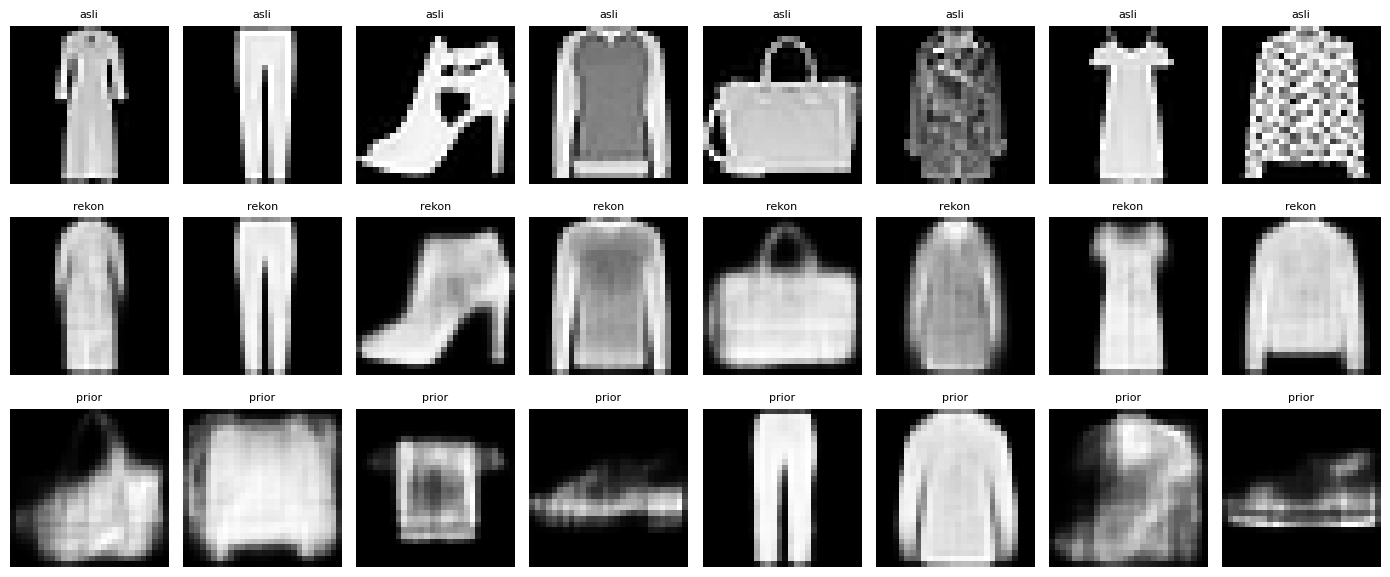

In [30]:
import matplotlib.pyplot as plt

model_vae.eval()
images, _ = next(iter(test))
images = images[:8].to(device)
with torch.no_grad():
    mu, _ = model_vae.encode(images)
    xr = model_vae.decoder(mu)
    z = torch.randn(8, 64, device=device)
    sampel = model_vae.decoder(z)

fig, ax = plt.subplots(3, 8, figsize=(14, 6))
for i in range(8):
    ax[0, i].imshow(images[i,0].cpu(), cmap='gray')
    ax[0, i].axis('off'); ax[0, i].set_title('asli', fontsize=8)
    ax[1, i].imshow(xr[i].cpu().reshape(28,28), cmap='gray')
    ax[1, i].axis('off'); ax[1, i].set_title('rekon', fontsize=8)
    ax[2, i].imshow(sampel[i].cpu().reshape(28,28), cmap='gray')
    ax[2, i].axis('off'); ax[2, i].set_title('prior', fontsize=8)

plt.tight_layout()
plt.show()

In [31]:
%%writefile src/variational_ae.py
import torch, torch.nn as nn, torch.nn.functional as F, time
from src.data import get_loaders
from src.utils import set_seed, get_device

class VAE(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28*28, 256), nn.ReLU()
        )
        self.fc_mu = nn.Linear(256, z_dim)
        self.fc_logvar = nn.Linear(256, z_dim)
        self.decoder = nn.Sequential(
            nn.Linear(z_dim, 256), nn.ReLU(),
            nn.Linear(256, 28*28), nn.Sigmoid()
        )
    def encode(self, x):
        h = self.encoder(x.flatten(1))
        return self.fc_mu(h), self.fc_logvar(h)
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar, z

def train_vae(epochs=30, lr=1e-3, batch_size=128, seed=42):
    set_seed(seed)
    device = get_device()
    train, val, test = get_loaders(batch_size, seed)
    model = VAE().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train': [], 'val': []}
    best_val, best_state, best_epoch = float('inf'), None, -1
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        train_loss_sum = 0
        for images, _ in train:
            images = images.to(device)
            optimizer.zero_grad()
            xr, mu, logvar, _ = model(images)
            bce = F.binary_cross_entropy(xr, images.flatten(1), reduction='mean')
            kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / images.size(0) / (28*28)
            loss = bce + kl
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * images.size(0)
        history['train'].append(train_loss_sum / len(train.dataset))

        model.eval()
        val_loss_sum = 0
        with torch.no_grad():
            for images, _ in val:
                images = images.to(device)
                xr, mu, logvar, _ = model(images)
                bce = F.binary_cross_entropy(xr, images.flatten(1), reduction='mean')
                kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / images.size(0) / (28*28)
                val_loss_sum += (bce + kl).item() * images.size(0)
        history['val'].append(val_loss_sum / len(val.dataset))

        if history['val'][-1] < best_val:
            best_val = history['val'][-1]
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
            best_epoch = epoch + 1

        train_loss = history['train'][-1]
        val_loss = history['val'][-1]
        print(f'Epoch {epoch+1:02d} : train {train_loss:.5f} , val {val_loss:.5f}')

    model.load_state_dict(best_state)
    return model, history, (time.time() - start_time) / epochs, best_epoch, best_val

Writing src/variational_ae.py


# 5. MLP Classifier

In [32]:
import torch, torch.nn as nn, torch.nn.functional as F, time
from src.data import get_loaders
from src.utils import set_seed, get_device

class MLPClassifier(nn.Module):
    def __init__(self, hidden1=256, dropout=0.0):
        super().__init__()
        self.features = nn.Sequential(
            nn.Linear(28*28, hidden1), nn.ReLU(),
            nn.Linear(hidden1, 64), nn.ReLU()
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(64, 10)
    def forward(self, x):
        z = self.features(x.flatten(1))
        return self.classifier(self.dropout(z)), z

def train_mlp(hidden1=256, dropout=0.0, epochs=20, lr=1e-3, batch_size=128, seed=42):
    set_seed(seed)
    device = get_device()
    train, val, test = get_loaders(batch_size, seed)
    model = MLPClassifier(hidden1, dropout).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    best_val, best_state = 0.0, None

    for epoch in range(epochs):
        model.train()
        for images, labels in train:
            images = images.to(device)
            labels = labels.to(device)
            optimizer.zero_grad()
            logits, _ = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
        model.eval()
        correct = 0
        with torch.no_grad():
            for images, labels in val:
                images = images.to(device)
                labels = labels.to(device)
                logits, _ = model(images)
                correct += (logits.argmax(1) == labels).sum().item()
        val_acc = correct / len(val.dataset)
        if val_acc > best_val:
            best_val = val_acc
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
        print(f'Epoch {epoch+1:02d} : val_acc {val_acc:.4f}')

    model.load_state_dict(best_state)
    return model, best_val

In [33]:
# Tahap 1: Pelatihan MLP Classifier Berjenjang: Latih MLP hingga akurasi test >= 88%
device = get_device()
_, _, test = get_loaders()

def hitung_test_acc(model):
    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in test:
            images = images.to(device)
            labels = labels.to(device)
            logits, _ = model(images)
            correct += (logits.argmax(1) == labels).sum().item()
    return correct / len(test.dataset)

konfigurasi_list = [
    {'hidden1': 256, 'dropout': 0.0},
    {'hidden1': 256, 'dropout': 0.2},
    {'hidden1': 512, 'dropout': 0.2},
]

model_mlp = None
test_acc = 0.0
konfigurasi_terpilih = None
for konfigurasi in konfigurasi_list:
    model, val_acc = train_mlp(**konfigurasi)
    akurasi_test = hitung_test_acc(model)
    print(f'{konfigurasi} : val {val_acc:.4f} , test {akurasi_test:.4f}')
    model_mlp = model
    test_acc = akurasi_test
    konfigurasi_terpilih = konfigurasi
    if akurasi_test >= 0.88:
        break

print('='*25)
print(f'konfigurasi terpilih: {konfigurasi_terpilih}')
print(f'test_acc: {test_acc:.4f}')
torch.save(model_mlp.state_dict(), 'mlp_classifier.pt')

Epoch 01 : val_acc 0.8447
Epoch 02 : val_acc 0.8513
Epoch 03 : val_acc 0.8633
Epoch 04 : val_acc 0.8704
Epoch 05 : val_acc 0.8750
Epoch 06 : val_acc 0.8731
Epoch 07 : val_acc 0.8774
Epoch 08 : val_acc 0.8819
Epoch 09 : val_acc 0.8824
Epoch 10 : val_acc 0.8821
Epoch 11 : val_acc 0.8790
Epoch 12 : val_acc 0.8851
Epoch 13 : val_acc 0.8856
Epoch 14 : val_acc 0.8907
Epoch 15 : val_acc 0.8807
Epoch 16 : val_acc 0.8883
Epoch 17 : val_acc 0.8923
Epoch 18 : val_acc 0.8947
Epoch 19 : val_acc 0.8861
Epoch 20 : val_acc 0.8856
{'hidden1': 256, 'dropout': 0.0} : val 0.8947 , test 0.8941
konfigurasi terpilih: {'hidden1': 256, 'dropout': 0.0}
test_acc: 0.8941


In [34]:
# simpan bobot w1,w2,w3 dan ambil z_mlp dari set test
import numpy as np

W1 = model_mlp.features[0].weight.detach().clone()
W2 = model_mlp.features[2].weight.detach().clone()
W3 = model_mlp.classifier.weight.detach().clone()
print('W1:', W1.shape, 'W2:', W2.shape, 'W3:', W3.shape)

model_mlp.eval()
z_list = []
y_list = []
x_list = []
with torch.no_grad():
    for images, labels in test:
        images = images.to(device)
        _, z = model_mlp(images)
        z_list.append(z.cpu())
        y_list.append(labels)
        x_list.append(images.cpu())
z_MLP = torch.cat(z_list, dim=0)
y_MLP = torch.cat(y_list, dim=0)
x_MLP = torch.cat(x_list, dim=0)
print('z_MLP: ', z_MLP.shape)
print('label: ', y_MLP.shape)

W1: torch.Size([256, 784]) W2: torch.Size([64, 256]) W3: torch.Size([10, 64])
z_MLP:  torch.Size([7000, 64])
label:  torch.Size([7000])


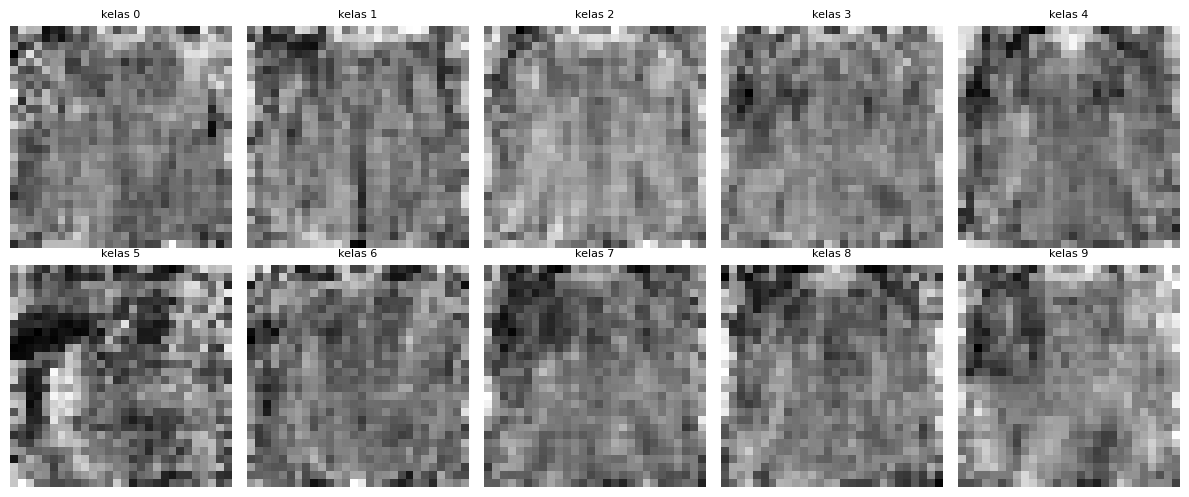

In [37]:
# Tahap 2: proyeksi balik dari vektor one-hot kelas target
# Tahap 2: z_hat = ReLu(w3^T y_c), dilanjut h1_hat = ReLu(w2^T z_hat), hingga x_hat = Sigmoid(w1^T h1_hat)
import matplotlib.pyplot as plt

def proyeksi_kelas(y_c):
    z_hat = F.relu(W3.T @ y_c)
    h_hat = F.relu(W2.T @ z_hat)
    x_hat = torch.sigmoid(W1.T @ h_hat)
    return x_hat.reshape(28, 28)

fig, ax = plt.subplots(2, 5, figsize=(12, 5))
hasil_tahap2 = []
for kelas in range(10):
    y_c = torch.zeros(10, device=device)
    y_c[kelas] = 1.0
    x_hat = proyeksi_kelas(y_c)
    hasil_tahap2.append(x_hat)
    ax[kelas // 5, kelas % 5].imshow(x_hat.cpu(), cmap='gray')
    ax[kelas // 5, kelas % 5].set_title(f'kelas {kelas}', fontsize=8)
    ax[kelas // 5, kelas % 5].axis('off')
plt.tight_layout()
plt.show()

In [39]:
mse_tahap2 = []
for kelas in range(10):
    idx = (y_MLP == kelas)
    rata2 = x_MLP[idx].mean(dim=0).squeeze()
    mse_kelas = float(((hasil_tahap2[kelas].cpu() - rata2)**2).mean())
    mse_tahap2.append(mse_kelas)
    print(f'kelas {kelas}: MSE vs rata-rata kelas = {mse_kelas:.3f}')
print(f'rata-rata MSE Tahap 2: {sum(mse_tahap2)/10:.3f}')

kelas 0: MSE vs rata-rata kelas = 0.098
kelas 1: MSE vs rata-rata kelas = 0.144
kelas 2: MSE vs rata-rata kelas = 0.076
kelas 3: MSE vs rata-rata kelas = 0.126
kelas 4: MSE vs rata-rata kelas = 0.093
kelas 5: MSE vs rata-rata kelas = 0.120
kelas 6: MSE vs rata-rata kelas = 0.077
kelas 7: MSE vs rata-rata kelas = 0.138
kelas 8: MSE vs rata-rata kelas = 0.078
kelas 9: MSE vs rata-rata kelas = 0.114
rata-rata MSE Tahap 2: 0.106


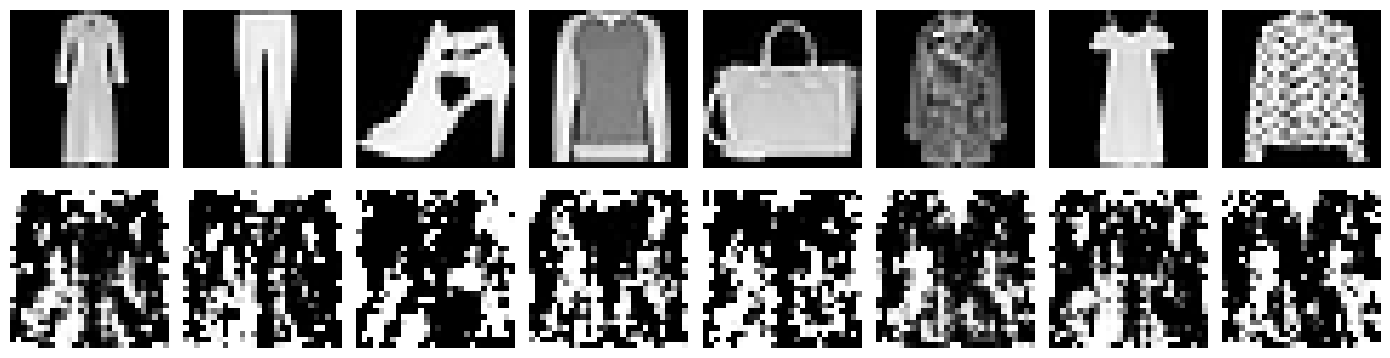

MSE Tahap 3: 0.3026


In [41]:
# Tahap 3: proyeksi balik dari z_MLP citra uji
# x_hat = Sigmoid(w1^T ReLu(w2^T z_mlp))
import matplotlib.pyplot as plt

idx_contoh = torch.arange(8)
z_contoh = z_MLP[idx_contoh].to(device)
x_asli = x_MLP[idx_contoh]

h_hat = F.relu(z_contoh @ W2)
x_hat = torch.sigmoid(h_hat @ W1)
x_hat = x_hat.cpu()

fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for i in range(8):
    ax[0, i].imshow(x_asli[i, 0].cpu(), cmap='gray'); ax[0, i].axis('off')
    ax[1, i].imshow(x_hat[i].reshape(28, 28).cpu(), cmap='gray'); ax[1, i].axis('off')
plt.tight_layout()
plt.show()

mse_tahap3 = float(((x_hat - x_asli.flatten(1))**2).mean())
print(f'MSE Tahap 3: {mse_tahap3:.4f}')

In [42]:
# Tahap 4: Evaluasi Kandungan Informasi Latent Features (Frozen Latent Decoding)
# frozen decoder (64->256->784 ) dengan MSE_loss pada z_mlp. lalu bandingkan metrik (mse, psnr, ssim) dengan Vanilla AutoEncoder
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np
from skimage.metrics import peak_signal_noise_ratio as psnr_fn, structural_similarity as ssim_fn
from src.utils import set_seed, get_device

class DecoderMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(64, 256), nn.ReLU(),
            nn.Linear(256, 28*28), nn.Sigmoid()
        )
    def forward(self, z):
        return self.net(z)

for p in model_mlp.parameters():
    p.requires_grad = False

set_seed(42)
device = get_device()
decoder_mlp = DecoderMLP().to(device)
optimizer = torch.optim.Adam(decoder_mlp.parameters(), lr=1e-3)
train, val, test = get_loaders()

def ekstrak_z(loader):
    zs, xs = [], []
    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            _, z = model_mlp(images)
            zs.append(z.cpu()); xs.append(images.cpu())
    return torch.cat(zs), torch.cat(xs)

z_train, x_train = ekstrak_z(train)
z_val, x_val = ekstrak_z(val)

for epoch in range(30):
    decoder_mlp.train()
    idx = torch.randperm(len(z_train))
    for i in range(0, len(z_train), 128):
        batch_idx = idx[i:i+128]
        z_batch = z_train[batch_idx].to(device)
        x_batch = x_train[batch_idx].to(device).flatten(1)
        optimizer.zero_grad()
        xr = decoder_mlp(z_batch)
        loss = F.mse_loss(xr, x_batch)
        loss.backward()
        optimizer.step()

decoder_mlp.eval()
with torch.no_grad():
    xr_test_mlp = decoder_mlp(z_MLP.to(device)).cpu()

mse_tahap4 = float(((xr_test_mlp - x_MLP.flatten(1))**2).mean())
psnr_list = []
ssim_list = []
for i in range(len(x_MLP)):
    asli = x_MLP[i, 0].numpy()
    hasil = xr_test_mlp[i].reshape(28, 28).numpy()
    psnr_list.append(psnr_fn(asli, hasil, data_range=1.0))
    ssim_list.append(ssim_fn(asli, hasil, data_range=1.0))
psnr_tahap4 = float(np.mean(psnr_list))
ssim_tahap4 = float(np.mean(ssim_list))

print('='*25)
print('FROZEN DECODER z_MLP')
print(f'MSE  {mse_tahap4:.3f}')
print(f'PSNR {psnr_tahap4:.2f}')
print(f'SSIM {ssim_tahap4:.3f}')
print('-'*25)
print('PEMBANDING VANILLA AE')
print(f'MSE {mse_ae:.3f}')
print(f'PSNR {psnr_ae:.2f}')
print(f'SSIM {ssim_ae:.3f}')

FROZEN DECODER z_MLP
MSE  0.017
PSNR 18.35
SSIM 0.659
-------------------------
PEMBANDING VANILLA AE
MSE 0.006
PSNR 23.02
SSIM 0.828


Statistik z_MLP (test set):
mu_z: torch.Size([64]) , rata-rata 1.4954
sigma_z: torch.Size([64]) , rata-rata 1.7915
persen nol: 50.31%
korelasi antar-dimensi rata-rata: nan


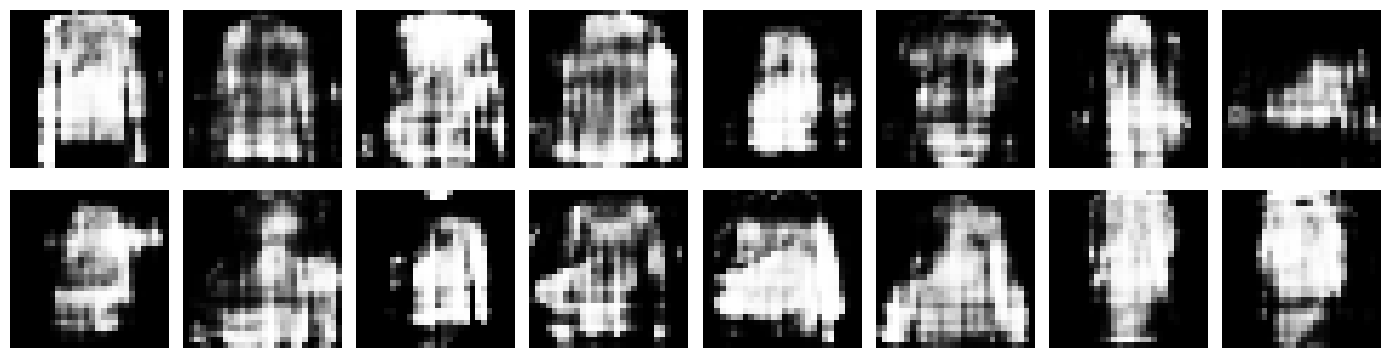

In [43]:
# Tahap 5: Uji Sampling Generatif pada Ruang Laten MLP Classifier
import numpy as np
import matplotlib.pyplot as plt

mu_z = z_MLP.mean(dim=0)
sigma_z = z_MLP.std(dim=0)
persen_nol = (z_MLP == 0).float().mean().item() * 100
korelasi = torch.corrcoef(z_MLP.T).abs().mean().item()

print('Statistik z_MLP (test set):')
print(f'mu_z: {mu_z.shape} , rata-rata {mu_z.mean().item():.4f}')
print(f'sigma_z: {sigma_z.shape} , rata-rata {sigma_z.mean().item():.4f}')
print(f'persen nol: {persen_nol:.2f}%')
print(f'korelasi antar-dimensi rata-rata: {korelasi:.4f}')

torch.manual_seed(42)
z_rand = mu_z + sigma_z * torch.randn(16, 64)
with torch.no_grad():
    x_rand = decoder_mlp(z_rand.to(device)).cpu()

fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for i in range(16):
    ax[i // 8, i % 8].imshow(x_rand[i].reshape(28, 28), cmap='gray')
    ax[i // 8, i % 8].axis('off')
plt.tight_layout()
plt.show()

In [47]:
# Membuktikan batasan halaman 2 (pdf): (2) matriks bobot persegi panjang 𝑊(𝑙) tidak bersifat ortogonal maupun invertibel
# serta fungsi aktivasi ReLU(𝑢) = 𝑚𝑎𝑥(0, 𝑢) memotong nilai negatif secara ireversibel;

import numpy as np

for nama, W in [('W1', W1), ('W2', W2), ('W3', W3)]:
    WtW = W.T @ W
    I = torch.eye(WtW.shape[0], device=WtW.device)
    frob = float(torch.norm(WtW - I, p='fro'))
    sv = torch.linalg.svdvals(W).cpu().numpy()
    print(f'{nama}: w^(l) = {frob:.4f}')
    print(f'singular values min/max = {sv.min():.4f}/{sv.max():.4f}')
    print()

W1: w^(l) = 417.0411
singular values min/max = 0.3661/13.2871

W2: w^(l) = 61.2356
singular values min/max = 0.3934/6.6981

W3: w^(l) = 11.0044
singular values min/max = 0.9043/2.5815



In [48]:
%%writefile src/mlp_classifier.py
import torch, torch.nn as nn, torch.nn.functional as F
from src.data import get_loaders
from src.utils import set_seed, get_device

class MLPClassifier(nn.Module):
    def __init__(self, hidden1=256, dropout=0.0):
        super().__init__()
        self.features = nn.Sequential(
            nn.Linear(28*28, hidden1), nn.ReLU(),
            nn.Linear(hidden1, 64), nn.ReLU()
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(64, 10)
    def forward(self, x):
        z = self.features(x.flatten(1))
        return self.classifier(self.dropout(z)), z

def train_mlp(hidden1=256, dropout=0.0, epochs=20, lr=1e-3, batch_size=128, seed=42):
    set_seed(seed)
    device = get_device()
    train, val, test = get_loaders(batch_size, seed)
    model = MLPClassifier(hidden1, dropout).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    best_val, best_state = 0.0, None
    for epoch in range(epochs):
        model.train()
        for images, labels in train:
            images = images.to(device)
            labels = labels.to(device)
            optimizer.zero_grad()
            logits, _ = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
        model.eval()
        correct = 0
        with torch.no_grad():
            for images, labels in val:
                images = images.to(device)
                labels = labels.to(device)
                logits, _ = model(images)
                correct += (logits.argmax(1) == labels).sum().item()
        val_acc = correct / len(val.dataset)
        if val_acc > best_val:
            best_val = val_acc
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
        print(f'Epoch {epoch+1:02d} : val_acc {val_acc:.4f}')
    model.load_state_dict(best_state)
    return model, best_val

Writing src/mlp_classifier.py


## 6. Vanilla GAN